In [9]:
import numpy as np
import pandas as pd
import rasterio as rio
import matplotlib.pyplot as plt
from pathlib import Path

In [10]:
ROOT    = Path.cwd().parent
RESULTS = ROOT / 'results'
FLOWDIR = RESULTS / 'extraction-rasters'
FIGURES = ROOT / 'figures'; FIGURES.mkdir(exist_ok=True)

import json
_cfg = json.load(open(RESULTS / 'sweep-config.json'))   # sweep grid defined once in 5-2-map-extraction
SCENARIOS, BETAS = _cfg['SCENARIOS'], _cfg['BETAS']
DEMAND, RESERVE, RES = 'M', 'M', '50km'

# road-freight rate (USD per tonne-km): central $0.12, swept for robustness
FREIGHT_RATES = {'low': 0.08, 'central': 0.12, 'high': 0.15}
YEARS = 28   # 2023-2050 inclusive

# 5-3 — Transport-cost analysis (CE scenario × β trade-off)

Converts the **domestic transport work** (Mt·km) recorded by `5-2-map-extraction` into a monetary cost, across all **5 CE scenarios × 6 β**. Shows (i) how demand reduction (the CE axis) lowers transport cost and (ii) the **conservation premium** of biodiversity-aware allocation (the β axis) within each scenario.

## Conservative lower bound
Only *inter-cell* road haulage is priced. Omitted terms — intra-cell haulage (~20–25 km logged as 0), capital cost of extra quarries (CON fragments extraction), land opportunity cost — all push the true cost **up**, so this is a defensible lower bound on the conservation premium.

## Method
$\text{cost} = \sum_{\text{flows}} \text{alloc(t)} \times \text{dist(km)} \times f$, with $f \in \{0.08, 0.12, 0.15\}$ $/t·km. Flow files store `alloc_Mt` & `dist_km`, so `cost = alloc_Mt × dist_km × 1e6 × f`.

## Inputs
- `domestic-flows-{scenario}-B{β}-{res}-D{Ld}-R{Lr}.csv` (30, from `5-2`)
- `rarity-weighted-richness-vertebrates-{res}.tif` (biodiversity exposure)

In [11]:
RWR = rio.open(RESULTS / f'area-of-habitat-{RES}' / f'rarity-weighted-richness-vertebrates-{RES}.tif').read(1)

In [12]:
def flow_path(scenario, beta):
    return FLOWDIR / f'domestic-flows-{scenario}-B{beta:.2f}-{RES}-D{DEMAND}-R{RESERVE}.csv'

rows = []
for scen in SCENARIOS:
    for b in BETAS:
        p = flow_path(scen, b)
        if not p.exists():
            print(f'  MISSING: {p.name}'); continue
        f = pd.read_csv(p)
        work  = (f['alloc_Mt'] * f['dist_km']).sum()                # Mt*km
        alloc = f['alloc_Mt'].sum()
        rwr_at = RWR[f['extract_i'].values, f['extract_j'].values]
        rows.append({
            'scenario': scen, 'beta': b,
            'work_Mt_km': work, 'work_Gt_km': work / 1e3,
            'mean_dist_km': work / alloc, 'alloc_Gt': alloc / 1e3,
            'rwr_exposure': (f['alloc_Mt'].values * rwr_at).sum() / alloc,
        })

cost_df = pd.DataFrame(rows)
cost_df.round(2)

,scenario,beta,work_Mt_km,work_Gt_km,mean_dist_km,alloc_Gt,rwr_exposure
0,BAU,0.00,9625796.95,9625.80,21.62,445.23,0.69
1,BAU,0.10,9634146.21,9634.15,21.64,445.23,0.66
2,BAU,0.20,9915169.14,9915.17,22.27,445.23,0.63
3,BAU,0.30,10895269.07,10895.27,24.47,445.23,0.55
4,BAU,0.40,12699260.61,12699.26,28.52,445.23,0.49
...,...,...,...,...,...,...,...
138,CE,0.80,24249025.70,24249.03,69.00,351.43,0.29
139,CE,0.85,28222865.47,28222.87,80.31,351.43,0.26
140,CE,0.90,32988880.46,32988.88,93.87,351.43,0.25
141,CE,0.95,40215498.49,40215.50,114.43,351.43,0.23


In [13]:
# freight rates -> cumulative transport cost (trillion USD, 2023-2050)
for label, rate in FREIGHT_RATES.items():
    cost_df[f'cost_Tusd_{label}'] = cost_df['work_Mt_km'] * 1e6 * rate / 1e12

# within-scenario conservation premium (vs that scenario's beta = 0), central rate
base_cost = cost_df[cost_df['beta'] == 0.0].set_index('scenario')['cost_Tusd_central']
base_rwr  = cost_df[cost_df['beta'] == 0.0].set_index('scenario')['rwr_exposure']
cost_df['premium_Tusd_central'] = cost_df['cost_Tusd_central'] - cost_df['scenario'].map(base_cost)
cost_df['premium_Busd_yr']      = cost_df['premium_Tusd_central'] * 1e3 / YEARS
cost_df['rwr_vs_b0_%']          = 100 * (cost_df['rwr_exposure'] / cost_df['scenario'].map(base_rwr) - 1)

# absolute cost vs the GLOBAL baseline (BAU, beta=0): captures the demand-reduction saving
global_base = cost_df[(cost_df['scenario'] == 'BAU') & (cost_df['beta'] == 0.0)]['cost_Tusd_central'].iloc[0]
cost_df['cost_vs_globalBAU_%'] = 100 * (cost_df['cost_Tusd_central'] / global_base - 1)

cost_df[['scenario','beta','work_Gt_km','cost_Tusd_central','premium_Tusd_central',
         'rwr_vs_b0_%','cost_vs_globalBAU_%']].round(3)

,scenario,beta,work_Gt_km,cost_Tusd_central,premium_Tusd_central,rwr_vs_b0_%,cost_vs_globalBAU_%
0,BAU,0.00,9625.797,1.155,0.000,0.000,0.000
1,BAU,0.10,9634.146,1.156,0.001,-4.127,0.087
2,BAU,0.20,9915.169,1.190,0.035,-8.610,3.006
3,BAU,0.30,10895.269,1.307,0.152,-20.337,13.188
4,BAU,0.40,12699.261,1.524,0.369,-29.470,31.929
...,...,...,...,...,...,...,...
138,CE,0.80,24249.026,2.910,2.035,-59.933,151.917
139,CE,0.85,28222.865,3.387,2.512,-63.126,193.200
140,CE,0.90,32988.880,3.959,3.084,-65.647,242.713
141,CE,0.95,40215.498,4.826,3.951,-67.759,317.789


In [14]:
# marginal cost of conservation per scenario: extra billion USD per %-point biodiversity exposure avoided
seg_list = []
for scen in SCENARIOS:
    s = cost_df[cost_df['scenario'] == scen].sort_values('beta').copy()
    d_cost = s['cost_Tusd_central'].diff() * 1e3       # billion USD increment
    d_rwr  = -s['rwr_vs_b0_%'].diff()                  # %-points avoided (positive as beta rises)
    s['marg_Busd_per_pct'] = (d_cost / d_rwr).replace([np.inf, -np.inf], np.nan)
    seg_list.append(s)
marg_df = pd.concat(seg_list)
marg_df[['scenario','beta','premium_Tusd_central','rwr_vs_b0_%','marg_Busd_per_pct']].round(2)

,scenario,beta,premium_Tusd_central,rwr_vs_b0_%,marg_Busd_per_pct
0,BAU,0.00,0.00,0.00,NaN
1,BAU,0.10,0.00,-4.13,0.24
2,BAU,0.20,0.03,-8.61,7.52
3,BAU,0.30,0.15,-20.34,10.03
4,BAU,0.40,0.37,-29.47,23.70
...,...,...,...,...,...
138,CE,0.80,2.03,-59.93,100.92
139,CE,0.85,2.51,-63.13,149.34
140,CE,0.90,3.08,-65.65,226.93
141,CE,0.95,3.95,-67.76,410.49


Saved: d:\wty\Documents\GitHub\aggregate-mining-biodiversity\figures\Fig-cost-tradeoff-DM-RM.jpg


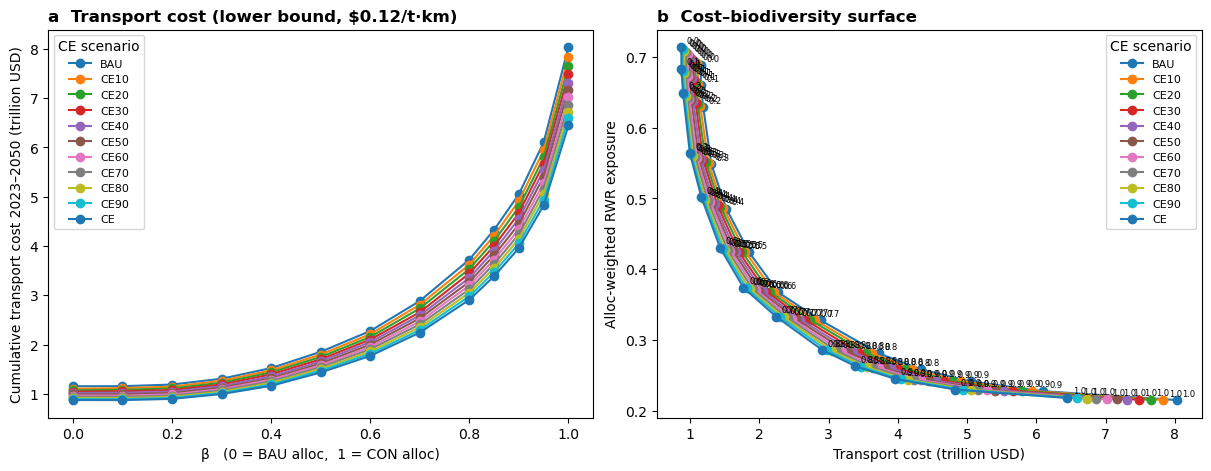

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)

# (a) cumulative transport cost vs beta, one curve per CE scenario
ax = axes[0]
for scen in SCENARIOS:
    s = cost_df[cost_df['scenario'] == scen].sort_values('beta')
    ax.plot(s['beta'], s['cost_Tusd_central'], 'o-', label=scen)
ax.set_xlabel('β   (0 = BAU alloc,  1 = CON alloc)')
ax.set_ylabel('Cumulative transport cost 2023–2050 (trillion USD)')
ax.set_title('a  Transport cost (lower bound, $0.12/t·km)', loc='left', fontweight='bold')
ax.legend(title='CE scenario', fontsize=8)

# (b) cost–biodiversity surface: cost vs RWR exposure, one curve per scenario
ax = axes[1]
for scen in SCENARIOS:
    s = cost_df[cost_df['scenario'] == scen].sort_values('beta')
    ax.plot(s['cost_Tusd_central'], s['rwr_exposure'], 'o-', label=scen)
    for _, r in s.iterrows():
        ax.annotate(f"{r['beta']:.1f}", (r['cost_Tusd_central'], r['rwr_exposure']),
                    textcoords='offset points', xytext=(4, 3), fontsize=6)
ax.set_xlabel('Transport cost (trillion USD)')
ax.set_ylabel('Alloc-weighted RWR exposure')
ax.set_title('b  Cost–biodiversity surface', loc='left', fontweight='bold')
ax.legend(title='CE scenario', fontsize=8)

out = FIGURES / f'Fig-cost-tradeoff-D{DEMAND}-R{RESERVE}.jpg'
fig.savefig(out, dpi=300, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()

In [16]:
out_csv = FLOWDIR / f'cost-analysis-D{DEMAND}-R{RESERVE}.csv'
cost_df.round(4).to_csv(out_csv, index=False)
print(f'Saved: {out_csv}  ({len(cost_df)} rows)')
cost_df.round(3)

Saved: d:\wty\Documents\GitHub\aggregate-mining-biodiversity\results\extraction-rasters\cost-analysis-DM-RM.csv  (143 rows)


,scenario,beta,work_Mt_km,work_Gt_km,mean_dist_km,alloc_Gt,rwr_exposure,cost_Tusd_low,cost_Tusd_central,cost_Tusd_high,premium_Tusd_central,premium_Busd_yr,rwr_vs_b0_%,cost_vs_globalBAU_%
0,BAU,0.00,9.625797e+06,9625.797,21.620,445.225,0.688,0.770,1.155,1.444,0.000,0.000,0.000,0.000
1,BAU,0.10,9.634146e+06,9634.146,21.639,445.225,0.660,0.771,1.156,1.445,0.001,0.036,-4.127,0.087
2,BAU,0.20,9.915169e+06,9915.169,22.270,445.225,0.629,0.793,1.190,1.487,0.035,1.240,-8.610,3.006
3,BAU,0.30,1.089527e+07,10895.269,24.471,445.225,0.548,0.872,1.307,1.634,0.152,5.441,-20.337,13.188
4,BAU,0.40,1.269926e+07,12699.261,28.523,445.225,0.485,1.016,1.524,1.905,0.369,13.172,-29.470,31.929
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138,CE,0.80,2.424903e+07,24249.026,69.000,351.435,0.286,1.940,2.910,3.637,2.035,72.672,-59.933,151.917
139,CE,0.85,2.822287e+07,28222.865,80.308,351.435,0.263,2.258,3.387,4.233,2.512,89.703,-63.126,193.200
140,CE,0.90,3.298888e+07,32988.880,93.869,351.435,0.245,2.639,3.959,4.948,3.084,110.129,-65.647,242.713
141,CE,0.95,4.021550e+07,40215.498,114.432,351.435,0.230,3.217,4.826,6.032,3.951,141.100,-67.759,317.789
